In [4]:
import pandas as pd
import s3fs

fs = s3fs.S3FileSystem(
    endpoint_url="https://minio.lab.sspcloud.fr",
    client_kwargs={"region_name": "us-east-1"},
)

EXTRACTION_EVO_2023 = "s3://mateomorin/legifrance/extraction/contingent_evolution/year=2023/extraction_2023.parquet"
EXTRACTION_2023 = "s3://mateomorin/legifrance/extraction_contingent/year=2023/extraction_2023.parquet"
METDATA_2023 = "s3://mateomorin/legifrance/metadata/acco_metadata_2023.parquet"

extraction_evo = pd.read_parquet(EXTRACTION_EVO_2023, filesystem=fs)
extraction = pd.read_parquet(EXTRACTION_2023, filesystem=fs)
metadata = pd.read_parquet(METDATA_2023, filesystem=fs)

In [5]:
extraction_evo.info()

<class 'pandas.DataFrame'>
RangeIndex: 3590 entries, 0 to 3589
Data columns (total 9 columns):
 #   Column                             Non-Null Count  Dtype 
---  ------                             --------------  ----- 
 0   reference                          3590 non-null   str   
 1   anneeSignature                     3590 non-null   int64 
 2   n_chunks                           3590 non-null   int64 
 3   erreur                             0 non-null      object
 4   presence_contingent_conventionnel  3590 non-null   bool  
 5   presence_substitution              3590 non-null   bool  
 6   contingents                        3590 non-null   object
 7   citation_exacte                    3526 non-null   str   
 8   justification_ou_reserve           3562 non-null   str   
dtypes: bool(2), int64(2), object(2), str(3)
memory usage: 1.6+ MB


In [6]:
extraction.info()

<class 'pandas.DataFrame'>
RangeIndex: 3590 entries, 0 to 3589
Data columns (total 8 columns):
 #   Column                             Non-Null Count  Dtype 
---  ------                             --------------  ----- 
 0   reference                          3590 non-null   str   
 1   anneeSignature                     3590 non-null   int64 
 2   presence_contingent_conventionnel  3590 non-null   bool  
 3   contingents                        3590 non-null   str   
 4   citation_exacte                    3422 non-null   str   
 5   justification_ou_reserve           3489 non-null   str   
 6   n_chunks                           3590 non-null   int64 
 7   erreur                             0 non-null      object
dtypes: bool(1), int64(2), object(1), str(4)
memory usage: 1.8+ MB


In [7]:
compare_extraction = extraction.merge(extraction_evo, on="reference", how="outer")

In [8]:
compare_extraction.info()

<class 'pandas.DataFrame'>
RangeIndex: 3590 entries, 0 to 3589
Data columns (total 16 columns):
 #   Column                               Non-Null Count  Dtype 
---  ------                               --------------  ----- 
 0   reference                            3590 non-null   str   
 1   anneeSignature_x                     3590 non-null   int64 
 2   presence_contingent_conventionnel_x  3590 non-null   bool  
 3   contingents_x                        3590 non-null   str   
 4   citation_exacte_x                    3422 non-null   str   
 5   justification_ou_reserve_x           3489 non-null   str   
 6   n_chunks_x                           3590 non-null   int64 
 7   erreur_x                             0 non-null      object
 8   anneeSignature_y                     3590 non-null   int64 
 9   n_chunks_y                           3590 non-null   int64 
 10  erreur_y                             0 non-null      object
 11  presence_contingent_conventionnel_y  3590 non-null   b

In [9]:
compare_extraction[pd.col("presence_contingent_conventionnel_x") != pd.col("presence_contingent_conventionnel_y")].to_dict(orient="index")

{363: {'reference': 'T01423060060',
  'anneeSignature_x': 2023,
  'presence_contingent_conventionnel_x': False,
  'contingents_x': '[]',
  'citation_exacte_x': '',
  'justification_ou_reserve_x': "Le texte mentionne un contingent de 220 heures, mais il précise explicitement qu'il est fixé 'en référence à l’article D.3121-14-1 du Code du travail'. Il s'agit donc d'un simple rappel du contingent légal et non de la création d'un contingent conventionnel propre à l'entreprise par dérogation ou spécificité conventionnelle.",
  'n_chunks_x': 5,
  'erreur_x': None,
  'anneeSignature_y': 2023,
  'n_chunks_y': 5,
  'erreur_y': None,
  'presence_contingent_conventionnel_y': True,
  'presence_substitution': False,
  'contingents_y': array([{'categorie_ou_population': 'salariés à temps complet', 'type_substitution': 'aucun', 'nombre_heures_avant_accord': 220.0, 'nombre_heures_apres_accord': None, 'periode': 'annuel'}],
        dtype=object),
  'citation_exacte_y': 'Le contingent annuel d’heures su

**Les 3 facteurs d'explicabilité** :

- l'ancien est plus conservateur au niveau des règles de majoration
- le nouveau essaie davantage de deviner avec d'autres informations (majoration, ...)
- le RAG est imprécis et laisse sujet à interprétation

In [10]:
import json

def develop_contingents(df):
    if len(df) == 0:
        return df
    df = df.copy()

    # Convert to correct dtype
    if isinstance(df["contingents"][0], str):
        contingents = df["contingents"].to_list()
        contingents = [json.loads(chaine) for chaine in contingents]
        df["contingents"] = contingents

    df = df.explode("contingents")
    # print(df.head())
    df_dict = pd.json_normalize(df["contingents"])
    df = pd.concat([df.drop(columns=["contingents"]), df_dict], axis=1)
    return df

In [11]:
extraction_developped = develop_contingents(extraction)

In [12]:
extraction_evo_developped = develop_contingents(extraction_evo)

In [13]:
extraction_developped.info()

<class 'pandas.DataFrame'>
Index: 3729 entries, 0 to 3589
Data columns (total 10 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   reference                          3729 non-null   str    
 1   anneeSignature                     3729 non-null   int64  
 2   presence_contingent_conventionnel  3729 non-null   bool   
 3   citation_exacte                    3558 non-null   str    
 4   justification_ou_reserve           3627 non-null   str    
 5   n_chunks                           3729 non-null   int64  
 6   erreur                             0 non-null      object 
 7   categorie_ou_population            2236 non-null   str    
 8   nombre_heures                      2240 non-null   float64
 9   periode                            2239 non-null   str    
dtypes: bool(1), float64(1), int64(2), object(1), str(5)
memory usage: 1.8+ MB


In [14]:
extraction_evo_developped.info()

<class 'pandas.DataFrame'>
Index: 3743 entries, 0 to 3589
Data columns (total 13 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   reference                          3743 non-null   str    
 1   anneeSignature                     3743 non-null   int64  
 2   n_chunks                           3743 non-null   int64  
 3   erreur                             0 non-null      object 
 4   presence_contingent_conventionnel  3743 non-null   bool   
 5   presence_substitution              3743 non-null   bool   
 6   citation_exacte                    3679 non-null   str    
 7   justification_ou_reserve           3715 non-null   str    
 8   categorie_ou_population            2256 non-null   str    
 9   type_substitution                  2256 non-null   str    
 10  nombre_heures_avant_accord         1334 non-null   float64
 11  nombre_heures_apres_accord         1352 non-null   float64
 12  periode 

In [15]:
extraction_evo_developped["presence_substitution"].sum()

np.int64(436)

In [16]:
extraction_evo_developped[~pd.col("nombre_heures_avant_accord").isna() & pd.col("presence_substitution")].sample(10).to_dict(orient="index")

{2364: {'reference': 'T07423006890',
  'anneeSignature': 2023,
  'n_chunks': 5,
  'erreur': None,
  'presence_contingent_conventionnel': True,
  'presence_substitution': True,
  'citation_exacte': 'Le présent accord a pour objet d’augmenter le contingent annuel d’heures supplémentaires et de le fixer à 420 heures par an et par salarié.',
  'justification_ou_reserve': "L'accord mentionne explicitement le contingent de la convention collective (180 heures) mais précise qu'il est augmenté par le présent accord d'entreprise pour être fixé à 420 heures par an et par salarié.",
  'categorie_ou_population': "salariés de l'entreprise Therm’Elec",
  'type_substitution': 'remplacement_contingent_legal',
  'nombre_heures_avant_accord': 180.0,
  'nombre_heures_apres_accord': 420.0,
  'periode': 'année civile'},
 1270: {'reference': 'T04423018822',
  'anneeSignature': 2023,
  'n_chunks': 5,
  'erreur': None,
  'presence_contingent_conventionnel': True,
  'presence_substitution': True,
  'citation_e

In [17]:
extraction_evo_developped[pd.col("nombre_heures_avant_accord").isna() ^ pd.col("nombre_heures_apres_accord").isna()].count()

reference                            1794
anneeSignature                       1794
n_chunks                             1794
erreur                                  0
presence_contingent_conventionnel    1794
presence_substitution                1794
citation_exacte                      1794
justification_ou_reserve             1768
categorie_ou_population              1794
type_substitution                    1794
nombre_heures_avant_accord            888
nombre_heures_apres_accord            906
periode                              1791
dtype: int64

In [19]:
extraction_evo_developped[pd.col("presence_substitution")]["citation_exacte"].sample(10).to_list()

['C’est pourquoi, en application de l’article L 3121-33 du code du travail, le contingent d’heures supplémentaires est porté à 572 heures par salarié et par année',
 '',
 'le contingent d’heures supplémentaires est fixé à trois cents (300) heures sur la période de référence définie au présent Accord.',
 'Le présent accord a pour objet d’augmenter le contingent annuel d’heures supplémentaires et de le fixer à 400 heures par an et par salarié.',
 "Le volume du contingent annuel d'heures supplémentaires est fixé à 370 heures par année civile et par salarié.",
 'Les signataires du présent accord décident de porter le contingent d’heures supplémentaires à 420 heures par année civile pour les salariés entrant dans le champ d’application et à temps plein',
 "En application de l'article L.3121-33 du Code du travail et en dérogation aux dispositions de l'accord de branche sur la durée et l'aménagement du temps de travail, le contingent annuel d'heures supplémentaires est porté à 220 heures par 

In [106]:
extraction_evo_developped[(~pd.col("nombre_heures_avant_accord").isna() & pd.col("nombre_heures_apres_accord").isna()) & pd.col("presence_substitution")].sample(10).to_dict(orient="index")

{954: {'reference': 'T03323014071',
  'anneeSignature': 2023,
  'n_chunks': 5,
  'erreur': None,
  'presence_contingent_conventionnel': True,
  'presence_substitution': True,
  'citation_exacte': 'Le contingent annuel d’heures supplémentaires est fixé à 400 heures. Le contingent est décompté sur une période annuelle débutant le 1er janvier et se terminant le 31 décembre.',
  'justification_ou_reserve': "L'accord fixe explicitement un contingent conventionnel de 400 heures, ce qui déroge au contingent légal. Le texte précise également les modalités de décompte annuel.",
  'categorie_ou_population': 'Salariés de la SARL G NI',
  'type_substitution': 'remplacement_contingent_legal',
  'nombre_heures_avant_accord': 400.0,
  'nombre_heures_apres_accord': nan,
  'periode': 'du 1er janvier au 31 décembre'},
 1059: {'reference': 'T03423008349',
  'anneeSignature': 2023,
  'n_chunks': 5,
  'erreur': None,
  'presence_contingent_conventionnel': True,
  'presence_substitution': True,
  'citation_

Le LLM fait des remplissages étranges : il sait qu'il y a changement du contingent, il a l'information de l'ancien contingent (qu'il mentionne), mais il n'affiche pas l'ancien contingent.

In [107]:
extraction_evo_developped["type_substitution"].value_counts()

type_substitution
aucun                            1264
remplacement_contingent_legal     971
remplacement_accord_anterieur      20
remplacement_branche                1
Name: count, dtype: int64

<Axes: >

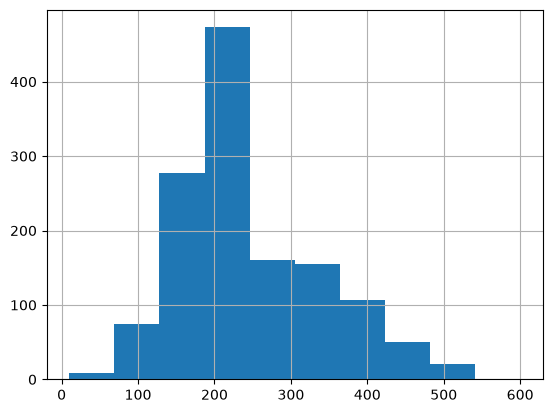

In [90]:
extraction_evo_developped[pd.col("nombre_heures_avant_accord") <= 600]["nombre_heures_avant_accord"].hist()

<Axes: >

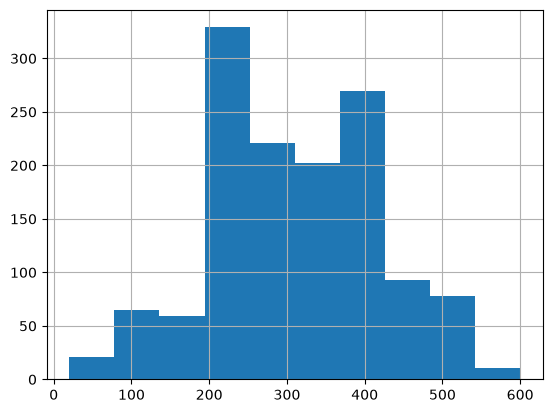

In [91]:
extraction_evo_developped[pd.col("nombre_heures_apres_accord") <= 600]["nombre_heures_apres_accord"].hist()